In [1]:
from requirements import *

# Extended Data Figure 10

In [2]:
adata_xenv2 = sc.read_h5ad(XEN_V2)
adata_cite = sc.read_h5ad(CITE)

## ED Figure 10a. TCR probe QC


In [3]:
tcrdi = {'ND_83': ['TRB:CASSPAWGQGDHEQYF;TRA:CAVDDYKLSF','TRB:CASSLGRGDEQYF;TRA:CAASLNDYKLSF;TRA:CAVGERNTDKLIF','TRB:CASGWSYEQYF;TRA:CAGQLDARLMF'],
         'ND_158': ['TRB:CASSLETVNEKLFF;TRA:CAFNSGGYQKVTF', 'TRB:CASSFGLAGRGDTQYF;TRA:CLTNNAGNMLTF', 'TRB:CASSRTGVASPLHF;TRA:CAAVSNAGNNRKLIW', 'TRB:CASRPETGGREAFF;TRA:CAESPWGQKLLF', 'TRB:CASSREVSWEQYF;TRA:CAGDGETSGSRLTF'],
         'ND_72': ['TRB:CASSYLGSEAFF;TRA:CAVQGRYNNNDMRF','TRB:CATSSRQGGYEQYF;TRA:CALTQGGYSTLTF','TRB:CASSSRTSGRYYNEQFF;TRA:CAASLDSSYKLIF'],
         'ND_150': ['TRB:CASSQPRTVLTQETQYF;TRA:CAASALIQGAQKLVF', 'TRB:CAIGPDRLDGYTF;TRA:CAITQGGSEKLVF', 'TRB:CASSIAGGYNEQFF;TRA:CAAPPPGFQKLVF']}

probe_di = {}
for samp in tcrdi:
    probe_di[samp] = []
    for tcr in tcrdi[samp]:
        trb = samp + '_' + tcr.split(';')[0]
        tra = samp + '_' + tcr.split(';')[1]
        probe_di[samp].append(trb)
        probe_di[samp].append(tra)

sample_ID_di = {'ND_72': ['region1_0033266', 'region1_0065647', 'region2_0065647', 'region1_0065644', 'region2_0065644'],
                     'ND_158': ['region1_0033274'],
                     'ND_83': ['region1_0033485'],
                     'ND_150': ['region1_0033484']}
df_probe = None
tmp_ad = adata_xenv2[adata_xenv2.obs['ct_general'].isin(['T Cell', 'NK'])]

for pat in probe_di:
    patsamples = sample_ID_di[pat]
    print(patsamples)
    for probe in probe_di[pat]:
        print(probe)
        df = sc.get.obs_df(tmp_ad, keys=[probe, 'sample_name'], use_raw= True)
        df.columns = ['tcr','sample']
        cutoff = []
        fpr = []
        num = []
        for i in range(int(max(df['tcr']) + 1)):
            print(i)
            cutoff.append(str(i))
            num.append(sum(df.loc[df['sample'].isin(patsamples)]['tcr'] >= i))
            if sum(df.loc[df['sample'].isin(patsamples)]['tcr'] >= i) == 0:
                fpr.append(1)
            else:
                expected_falsepos = (sum(df.loc[~(df['sample'].isin(patsamples))]['tcr'] >= i)/df.loc[~(df['sample'].isin(patsamples))].shape[0]) * df.loc[df['sample'].isin(patsamples)].shape[0]
                val = expected_falsepos/sum(df.loc[df['sample'].isin(patsamples)]['tcr'] >= i) # proportion of positives that are expected to be false positives
                fpr.append(min(val,1))
        currdf = pd.DataFrame(list(zip(cutoff, fpr, num)),columns=['Probe Quantity Cutoff', 'Predicted FDR', 'Num Cells'])
        currdf['Probe'] = probe
        currdf['Patient'] = pat
        df_probe = pd.concat([df_probe, currdf])

df_probe.reset_index(drop=True, inplace=True)
df_probe['cutoff'] = [int(x) for x in df_probe['Probe Quantity Cutoff']]
df_probe['log10(Num Cells)'] = np.log10(df_probe['Num Cells'])
df_probe = df_probe[df_probe['Probe'].isin([x for x in df_probe[df_probe['Predicted FDR'] < 0.05].drop_duplicates(subset=['Probe'], keep='first')['Probe'] if not x == 'ND_158_TRA:CLTNNAGNMLTF'])] #'ND_158_TRA:CLTNNAGNMLTF' removed: not specific to a single TCRb


['region1_0033485']
ND_83_TRB:CASSPAWGQGDHEQYF
0
1
2
3
4
5
ND_83_TRA:CAVDDYKLSF
0
1
2
3
ND_83_TRB:CASSLGRGDEQYF
0
1
2
ND_83_TRA:CAASLNDYKLSF
0
1
2
3
4
ND_83_TRB:CASGWSYEQYF
0
1
2
ND_83_TRA:CAGQLDARLMF
0
1
2
['region1_0033274']
ND_158_TRB:CASSLETVNEKLFF
0
1
2
ND_158_TRA:CAFNSGGYQKVTF
0
1
2
ND_158_TRB:CASSFGLAGRGDTQYF
0
1
2
3
4
ND_158_TRA:CLTNNAGNMLTF
0
1
2
ND_158_TRB:CASSRTGVASPLHF
0
1
2
3
4
ND_158_TRA:CAAVSNAGNNRKLIW
0
1
2
ND_158_TRB:CASRPETGGREAFF
0
1
2
3
ND_158_TRA:CAESPWGQKLLF
0
1
2
3
ND_158_TRB:CASSREVSWEQYF
0
1
2
ND_158_TRA:CAGDGETSGSRLTF
0
1
['region1_0033266', 'region1_0065647', 'region2_0065647', 'region1_0065644', 'region2_0065644']
ND_72_TRB:CASSYLGSEAFF
0
1
2
3
ND_72_TRA:CAVQGRYNNNDMRF
0
1
2
3
ND_72_TRB:CATSSRQGGYEQYF
0
1
ND_72_TRA:CALTQGGYSTLTF
0
1
ND_72_TRB:CASSSRTSGRYYNEQFF
0
1
2
ND_72_TRA:CAASLDSSYKLIF
0
1
2
3
['region1_0033484']
ND_150_TRB:CASSQPRTVLTQETQYF
0
1
ND_150_TRA:CAASALIQGAQKLVF
0
1
ND_150_TRB:CAIGPDRLDGYTF
0
1
ND_150_TRA:CAITQGGSEKLVF
0
1
ND_150_TRB:CASSIAGGYN

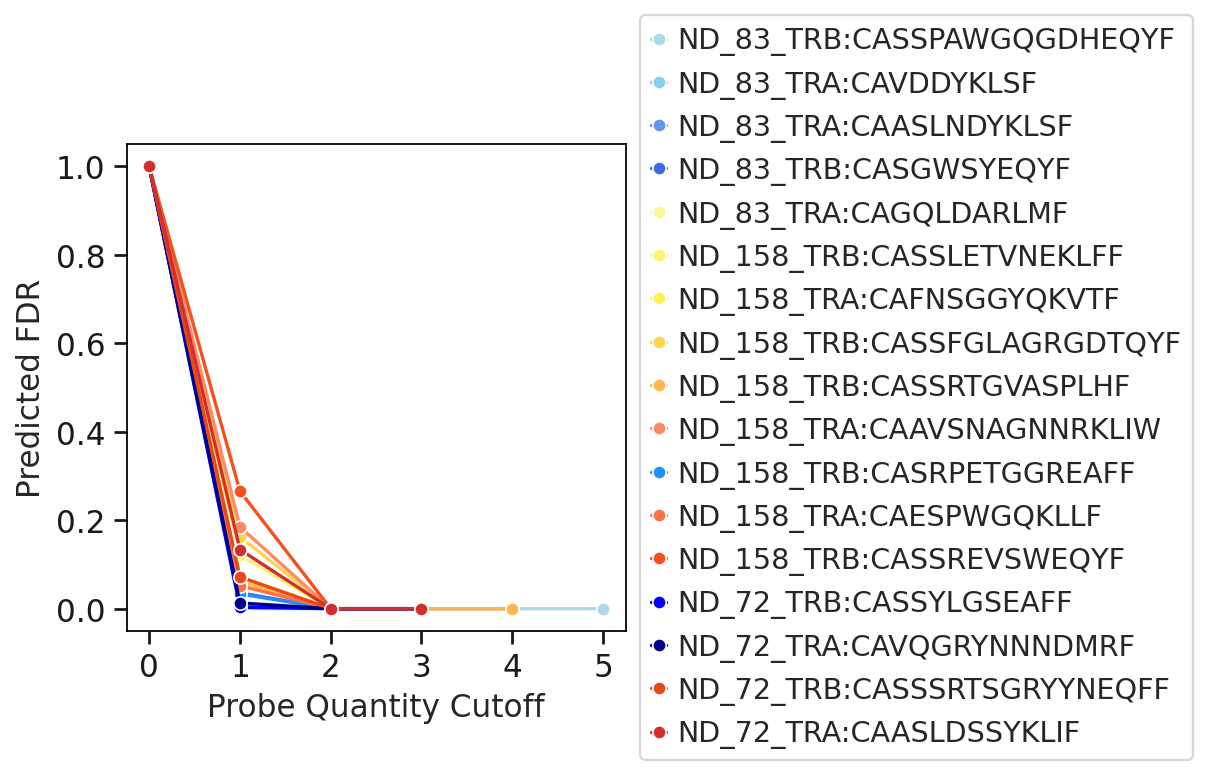

In [4]:
sns.set_style("ticks")
plt.rcParams['patch.edgecolor'] = 'black'
sc.set_figure_params(figsize=(4, 4))

cmp = ['#FFC1C1', '#FA8072', '#FF4C4C', '#FF0000', '#DC143C', '#800020', '#4B0000']  + ['#E0F7FA', '#B3E5FC', '#81D4FA', '#4FC3F7', '#29B6F6', '#03A9F4', '#039BE5', '#0288D1', '#0277BD', '#01579B', '#003F7D']
cmp = ['#ADD8E6', '#87CEEB', '#6495ED', '#4169E1', '#1E90FF', '#0000FF', '#00008B'] + ['#FFF59D', '#FFF176', '#FFEE58', '#FFD54F', '#FFB74D', '#FF8A65', '#FF7043', '#F4511E', '#E64A19', '#D32F2F']
cmp = ['#ADD8E6', '#87CEEB', '#6495ED', '#4169E1', '#FFF59D', '#FFF176', '#FFEE58', '#FFD54F', '#FFB74D', '#FF8A65', '#1E90FF', '#FF7043', '#F4511E', '#0000FF', '#00008B', '#E64A19', '#D32F2F']
df_probe = df_probe[df_probe['cutoff'] <= 5]
sns.lineplot(data=df_probe, x="Probe Quantity Cutoff", y="Predicted FDR", hue = 'Probe', marker='o', palette = cmp)
plt.grid(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

## ED Figure 10e. CITE-seq TCRa/b pairing of targeted TCRs


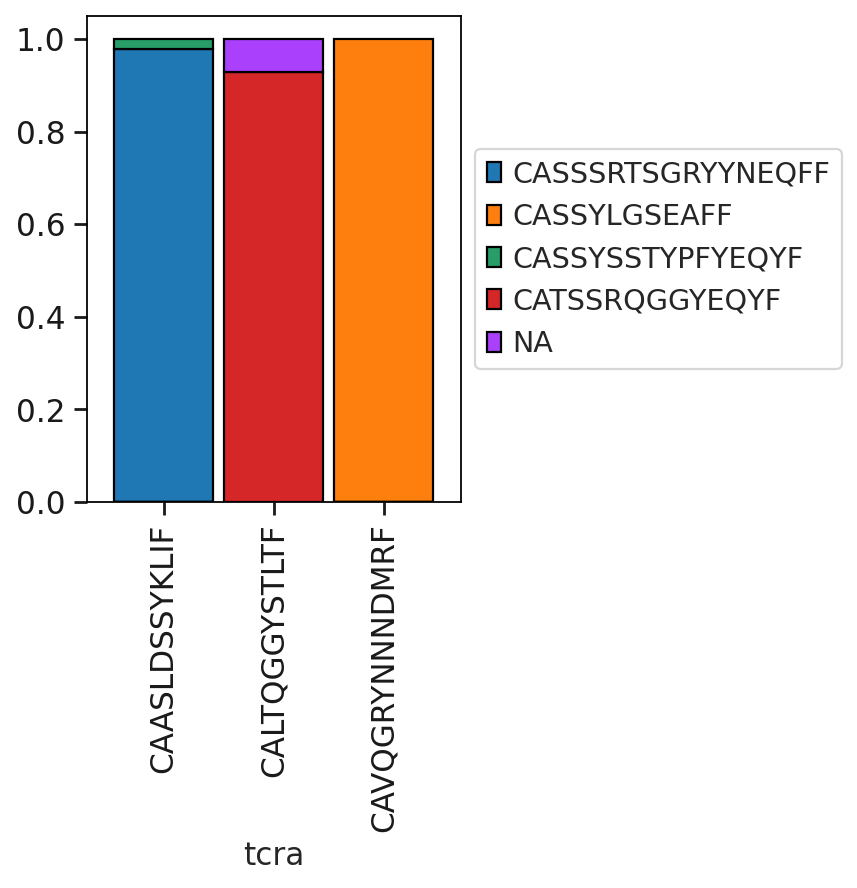

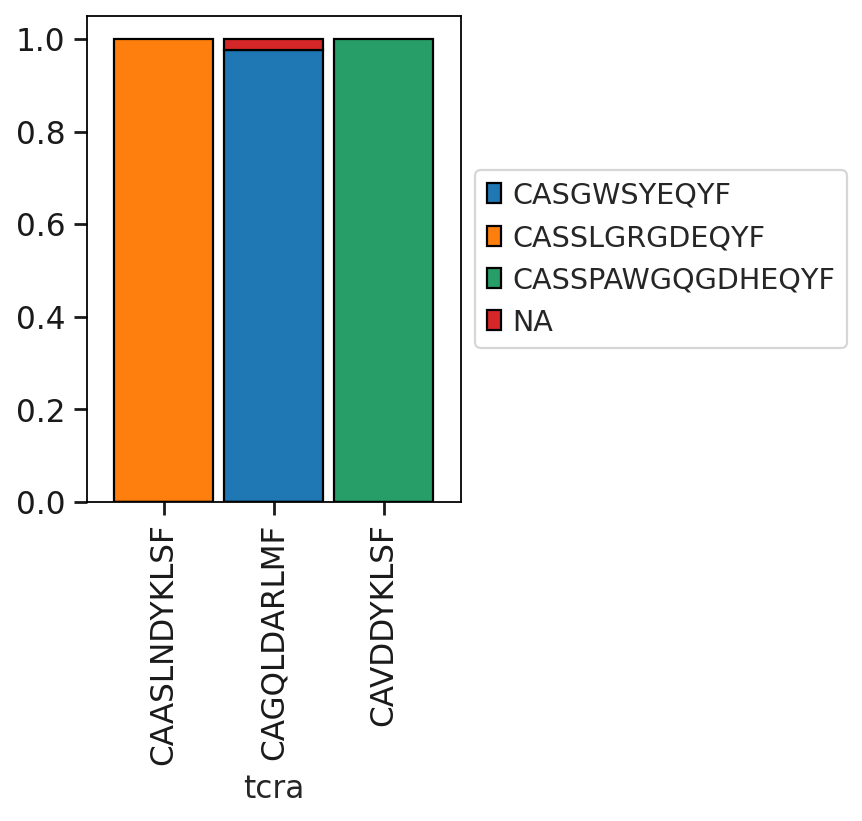

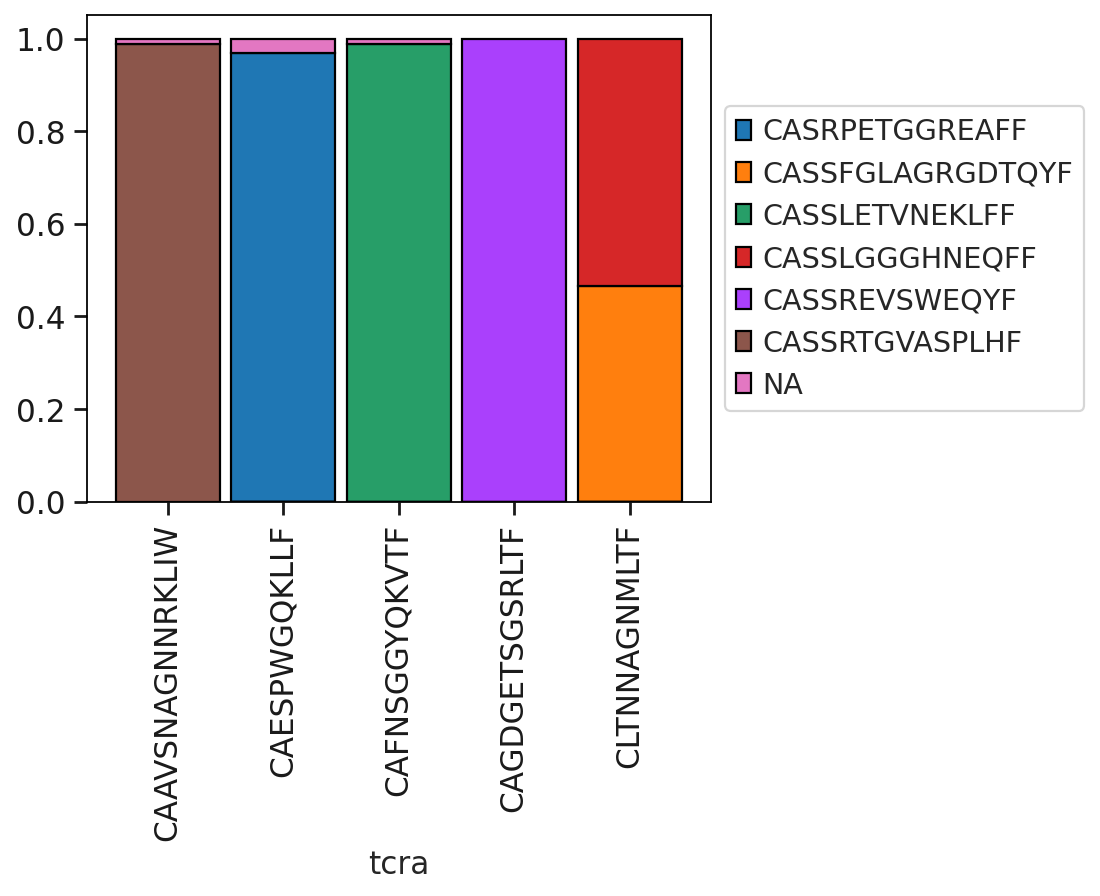

In [17]:
adata_cite.obs['tcra'] = [x.split('TRA:')[1].split(';')[0] if 'TRA:' in str(x) else 'NA' for x in adata_cite.obs['tcr']]

sc.set_figure_params(figsize=(3, 4))
tcrdi = {'ND_83': ['TRB:CASSPAWGQGDHEQYF;TRA:CAVDDYKLSF','TRB:CASSLGRGDEQYF;TRA:CAASLNDYKLSF;TRA:CAVGERNTDKLIF','TRB:CASGWSYEQYF;TRA:CAGQLDARLMF'],
         'ND_158': ['TRB:CASSLETVNEKLFF;TRA:CAFNSGGYQKVTF', 'TRB:CASSFGLAGRGDTQYF;TRA:CLTNNAGNMLTF', 'TRB:CASSRTGVASPLHF;TRA:CAAVSNAGNNRKLIW', 'TRB:CASRPETGGREAFF;TRA:CAESPWGQKLLF', 'TRB:CASSREVSWEQYF;TRA:CAGDGETSGSRLTF'],
         'ND_72': ['TRB:CASSYLGSEAFF;TRA:CAVQGRYNNNDMRF','TRB:CATSSRQGGYEQYF;TRA:CALTQGGYSTLTF','TRB:CASSSRTSGRYYNEQFF;TRA:CAASLDSSYKLIF'],
         'ND_150': ['TRB:CASSQPRTVLTQETQYF;TRA:CAASALIQGAQKLVF', 'TRB:CAIGPDRLDGYTF;TRA:CAITQGGSEKLVF', 'TRB:CASSIAGGYNEQFF;TRA:CAAPPPGFQKLVF']}

tmp = adata_cite 
tmp = tmp[tmp.obs['ct_general'].isin(['T Cell','NK'])]

tmp1 = tmp[tmp.obs['patient'] == 'ND72_T1']
tmp1 = tmp1[tmp1.obs['tcra'].isin([x.split(';')[1].split(':')[1] for x in tcrdi['ND_72']])]
df = pd.crosstab(index=tmp1.obs['tcra'], columns=tmp1.obs['tcrb'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9, edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)

tmp1 = tmp[tmp.obs['patient'] == 'ND83_T1']
tmp1 = tmp1[tmp1.obs['tcra'].isin([x.split(';')[1].split(':')[1] for x in tcrdi['ND_83']])]
df = pd.crosstab(index=tmp1.obs['tcra'], columns=tmp1.obs['tcrb'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9, edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)

sc.set_figure_params(figsize=(5, 4))
tmp1 = tmp[tmp.obs['patient'] == 'ND158_T1']
tmp1 = tmp1[tmp1.obs['tcra'].isin([x.split(';')[1].split(':')[1] for x in tcrdi['ND_158']])]
df = pd.crosstab(index=tmp1.obs['tcra'], columns=tmp1.obs['tcrb'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9, edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
